# IS463 Project: Saudi Real Estate Price Prediction (Group 5)

We predict the **price per square meter (SAR/m²)** of real estate sales transactions published quarterly by the Ministry of Justice on the Saudi Open Data Portal.

Two data mining tasks on the same prepared data:
* **Task A – Regression:** predict the exact price per m² (Linear Regression, Decision Tree Regressor, Neural Network).
* **Task B – Classification:** predict the price category Low / Medium / High (Decision Tree, Neural Network).

**Sequence:** load, inspect, clean, create target, split, handle outliers and missing values using training data only, encode, train, evaluate, compare, predict.


# Loading Data

In [ ]:
import pandas as pd  # pandas works with tables (DataFrames).
import numpy as np  # numerical operations and np.nan for missing values.
import os  # find the quarterly files in a folder.
import matplotlib.pyplot as plt  # plots for the paper and presentation.
from IPython.display import display  # show more than one table in a cell.

pd.set_option('display.max_columns', 50)  # show all columns when displaying tables.

## 1. Load and combine the quarterly datasets

The data is stored in the `data/` folder, one file per quarter, named by quarter (e.g. `2026_Q2.xlsx`).
We combine all quarters into one table and add a `Source_Quarter` column so every row remembers which file it came from.

In [ ]:
# Folder that holds the 22 quarterly Excel files, named by quarter (e.g. 2026_Q2.xlsx).
DATA_DIR = 'data'

# To run in Google Colab with the files on Google Drive, uncomment these lines instead:
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_DIR = '/content/drive/MyDrive/<your folder>/data'

print('Files in data folder:', sorted(os.listdir(DATA_DIR)))

Files in data folder: ['2020_Q1.xlsx', '2020_Q2.xlsx', '2020_Q3.xlsx', '2020_Q4.xlsx', '2021_Q1.xlsx', '2021_Q2.xlsx', '2021_Q3.xlsx', '2021_Q4.xlsx', '2022_Q1.xlsx', '2022_Q2.xlsx', '2022_Q3.xlsx', '2022_Q4.xlsx', '2024_Q1.xlsx', '2024_Q2.xlsx', '2024_Q3.xlsx', '2024_Q4.xlsx', '2025_Q1.xlsx', '2025_Q2.xlsx', '2025_Q3.xlsx', '2025_Q4.xlsx', '2026_Q1.xlsx', '2026_Q2.xlsx']


In [ ]:
# Find every Excel file in the data folder, sorted by name (i.e. by quarter).
files = sorted(os.path.join(DATA_DIR, name) for name in os.listdir(DATA_DIR)
               if name.lower().endswith('.xlsx'))
print('Files found:', len(files))

quarters = []
for path in files:
    table = pd.read_excel(path)  # Reads the first sheet of the Excel file.
    table['Source_Quarter'] = os.path.splitext(os.path.basename(path))[0]  # e.g. '2026_Q2'
    quarters.append(table)
    print(f"{table['Source_Quarter'].iloc[0]}: {table.shape[0]:,} rows, {table.shape[1]-1} columns")

# Check that every quarter has the SAME column names before combining.
column_sets = {tuple(t.columns) for t in quarters}
print('Same columns in all files:', len(column_sets) == 1)

Files found: 22
2020_Q1: 80,634 rows, 10 columns
2020_Q2: 49,618 rows, 10 columns
2020_Q3: 64,316 rows, 10 columns
2020_Q4: 82,243 rows, 10 columns
2021_Q1: 92,963 rows, 10 columns
2021_Q2: 66,671 rows, 10 columns
2021_Q3: 55,911 rows, 10 columns
2021_Q4: 66,338 rows, 10 columns
2022_Q1: 71,251 rows, 10 columns
2022_Q2: 53,016 rows, 10 columns
2022_Q3: 45,976 rows, 10 columns
2022_Q4: 43,511 rows, 10 columns
2024_Q1: 59,099 rows, 10 columns
2024_Q2: 48,271 rows, 10 columns
2024_Q3: 69,020 rows, 10 columns
2024_Q4: 72,938 rows, 10 columns
2025_Q1: 65,728 rows, 10 columns
2025_Q2: 42,518 rows, 10 columns
2025_Q3: 48,820 rows, 10 columns
2025_Q4: 44,490 rows, 10 columns
2026_Q1: 32,586 rows, 10 columns
2026_Q2: 34,664 rows, 10 columns
Same columns in all files: True


In [ ]:
# Stack all quarters into one table and keep an untouched copy of the raw data.
raw_df = pd.concat(quarters, ignore_index=True)
df = raw_df.copy()

print('Combined rows and columns:', df.shape)
print('Column names:', list(df.columns))
display(df.head(8))

Combined rows and columns: (1290582, 11)
Column names: ['المنطقة', 'المدينة', 'المدينة / الحي', 'الرقم المرجعي للصفقة', 'تاريخ الصفقة ميلادي', 'تاريخ الصفقة هجري', 'تصنيف العقار', 'عدد العقارات', 'السعر', 'المساحة', 'Source_Quarter']


,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة,Source_Quarter
0,منطقة مكة المكرمه,الطائف,الطائف/ طيبة,9470090,2020/01/01,1441/05/06,سكني,1,300000.0,835.50,2020_Q1
1,منطقة مكة المكرمه,الطائف,الطائف/ الجودية,9472004,2020/01/01,1441/05/06,سكني,1,54000.0,900.00,2020_Q1
2,منطقة مكة المكرمه,الطائف,الطائف/ حي البوادي,9471841,2020/01/01,1441/05/06,سكني,1,75000.0,677.50,2020_Q1
3,منطقة مكة المكرمه,الطائف,الطائف/ الكدى,9473011,2020/01/01,1441/05/06,سكني,1,100000.0,665.14,2020_Q1
4,منطقة مكة المكرمه,الطائف,الطائف/ الكدى,9472659,2020/01/01,1441/05/06,سكني,1,100000.0,665.14,2020_Q1
5,منطقة الرياض,الرياض,الرياض/البديعة,9471107,2020/01/01,1441/05/06,سكني,1,1050000.0,500.00,2020_Q1
6,منطقة الرياض,الرياض,الرياض/الحائر,9470692,2020/01/01,1441/05/06,سكني,1,145000.0,360.00,2020_Q1
7,منطقة الرياض,الرياض,الرياض/الحائر,9470900,2020/01/01,1441/05/06,سكني,1,150000.0,400.00,2020_Q1


## 2. Inspect before making changes

Look for missing values, numeric columns stored as text, inconsistent labels and repeated records.

In [ ]:
# Report storage types and recognized missing values for each column.
display(pd.DataFrame({'Data type': df.dtypes.astype(str),
                      'Missing values': df.isna().sum(),
                      'Unique values': df.nunique()}))

# Count exact duplicate rows across all quarters.
print('Extra duplicate rows:', df.duplicated().sum())

# Show the categories of the low-cardinality text columns (region, classification, etc.).
for column in df.columns:
    if df[column].dtype == object and df[column].nunique() <= 20:
        print(f'\n{column}:', df[column].unique())

,Data type,Missing values,Unique values
المنطقة,object,0,13
المدينة,object,0,168
المدينة / الحي,object,0,12281
الرقم المرجعي للصفقة,int64,0,1290582
تاريخ الصفقة ميلادي,object,0,2005
تاريخ الصفقة هجري,object,0,2005
تصنيف العقار,object,0,4
عدد العقارات,int64,0,50
السعر,float64,0,142136
المساحة,float64,0,123795


Extra duplicate rows: 0

المنطقة: ['منطقة مكة المكرمه' 'منطقة الرياض' 'منطقة نجران' 'منطقة عسير'
 'منطقة الشرقية' 'منطقة جازان' 'منطقة القصيم' 'منطقة الباحة'
 'منطقة المدينة المنوره' 'منطقة الحدود الشمالية' 'منطقة تبوك' 'منطقة حائل'
 'منطقة الجوف']

تصنيف العقار: ['سكني' 'زراعي' 'تجاري' 'سكني تجاري']


## Check the combined "City / District" column

The column `المدينة / الحي` stores the city and the district together in one text value, separated by `/` (for example `الرياض / حي النرجس`).
Before we use it, we check two things:

* **Does the city part match the `المدينة` column?** We split the text at `/`, take the first part, remove extra spaces and compare it with the separate city column. A result of **1.0** means they match in 100% of the rows.
* **Does every row contain exactly one `/`?** A result of **1.0** means every value splits cleanly into one city part and one district part, with no missing or extra separators.

In [ ]:
city_part = df['المدينة / الحي'].str.split('/').str[0].str.strip()
print('City part matches city column:', (city_part == df['المدينة'].str.strip()).mean())
print('Rows with exactly one "/":', (df['المدينة / الحي'].str.count('/') == 1).mean())

City part matches city column: 1.0
Rows with exactly one "/": 1.0


# Data Cleaning

## 3. Remove attributes we do not need

* `الرقم المرجعي للصفقة` (reference number) is an identifier, not a predictor.
* `تاريخ الصفقة ميلادي` and `تاريخ الصفقة هجري` (dates): the time information is kept in `Source_Quarter`, from which we build the `Time` attribute.
* `المدينة` (city) is repeated inside `المدينة / الحي`, as verified above.

In [ ]:
# Drop the identifier, the two date columns and the repeated city column.
df = df.drop(columns=['الرقم المرجعي للصفقة', 'تاريخ الصفقة ميلادي',
                      'تاريخ الصفقة هجري', 'المدينة'])
print('Attributes remaining:', list(df.columns))

Attributes remaining: ['المنطقة', 'المدينة / الحي', 'تصنيف العقار', 'عدد العقارات', 'السعر', 'المساحة', 'Source_Quarter']


## 4. Rename the attributes in English

Short English names make the code and the tables in the paper easier to read.

In [ ]:
# Give each remaining attribute a short English name.
df = df.rename(columns={'المنطقة': 'Region', 'المدينة / الحي': 'City_District',
                        'تصنيف العقار': 'Classification', 'عدد العقارات': 'Num_Properties',
                        'السعر': 'Price', 'المساحة': 'Area'})
print('Attributes now:', list(df.columns))
display(df.head())

Attributes now: ['Region', 'City_District', 'Classification', 'Num_Properties', 'Price', 'Area', 'Source_Quarter']


,Region,City_District,Classification,Num_Properties,Price,Area,Source_Quarter
0,منطقة مكة المكرمه,الطائف/ طيبة,سكني,1,300000.0,835.50,2020_Q1
1,منطقة مكة المكرمه,الطائف/ الجودية,سكني,1,54000.0,900.00,2020_Q1
2,منطقة مكة المكرمه,الطائف/ حي البوادي,سكني,1,75000.0,677.50,2020_Q1
3,منطقة مكة المكرمه,الطائف/ الكدى,سكني,1,100000.0,665.14,2020_Q1
4,منطقة مكة المكرمه,الطائف/ الكدى,سكني,1,100000.0,665.14,2020_Q1


## Make district names consistent

The same district is not always written the same way. Names can differ in:
* spaces around `/` (`الرياض/حطين`, `الرياض/ حطين`)
* the word `حي` before the name (`حي الملقا`, `الملقا`)
* letters that are often typed differently (`أ / إ / آ`, `ة / ه`, `ى / ي`), diacritics and tatweel (ـ)
* double spaces inside the name

If one district is written in two ways, its sales are split between two names. We rewrite every name in one format: diacritics and tatweel removed, `أ/إ/آ` → `ا`, `ة` → `ه`, `ى` → `ي`, no leading `حي`, single spaces between words, and exactly one space on each side of `/` (e.g. `الرياض / حطين`).
This is a fixed formatting rule, not something learned from the data, so it is applied before splitting.

In [ ]:
import re

def clean_place(text):
    # Write every 'City/District' name in one consistent format.
    text = str(text)
    text = re.sub(r'[\u064B-\u0652\u0640]', '', text)                       # remove diacritics and tatweel
    text = re.sub('[أإآ]', 'ا', text).replace('ة', 'ه').replace('ى', 'ي')    # unify letters often typed differently
    city, _, district = text.partition('/')
    district = re.sub(r'^حي\s+', '', district.strip())                       # drop a leading 'حي'
    return re.sub(r'\s+', ' ', city.strip()) + ' / ' + re.sub(r'\s+', ' ', district)  # single spaces

before = df['City_District'].nunique()
df['City_District'] = df['City_District'].map(clean_place)
print('District names before:', before)
print('District names after cleaning:', df['City_District'].nunique())
display(df['City_District'].head())

District names before: 12281
District names after cleaning: 11770


,City_District
0,الطائف / طيبه
1,الطائف / الجوديه
2,الطائف / البوادي
3,الطائف / الكدي
4,الطائف / الكدي


**Result:** 12,281 district names became 11,770: 511 names were different spellings of a district that already existed, mostly because of letters typed in different ways (ة/ه, ى/ي, أ/إ/ا) and spaces around `/`. The `head()` table shows the new format, e.g. `الطائف / طيبه` (ة written as ه after normalizing).

## 5. Check for impossible values

There are no missing values, but price and area must be greater than zero, and a transaction must contain at least one property.
An impossible price or area means the target cannot be calculated, so these transactions are removed instead of guessed.

In [ ]:
# Detect impossible values in the numeric attributes.
bad_price = df['Price'] <= 0
bad_area = df['Area'] <= 0
bad_count = df['Num_Properties'] < 1
display(pd.Series({'Price <= 0': bad_price.sum(), 'Area <= 0': bad_area.sum(),
                   'Num_Properties < 1': bad_count.sum()}))

# Remove transactions with impossible values.
df = df.loc[~(bad_price | bad_area | bad_count)].copy()
print('Transactions remaining:', len(df))

,0
Price <= 0,0
Area <= 0,0
Num_Properties < 1,0


Transactions remaining: 1290582


## 6. Choose the property classifications to study

First we count the transactions in each property classification.

In [ ]:
# Count transactions per property classification.
display(df['Classification'].value_counts().rename('Transactions'))

,Transactions
Classification,
سكني,1112767
تجاري,130352
زراعي,47461
سكني تجاري,2


Next we compare the price per m² of each classification. This is only an inspection: the target attribute is created later, in section 8.

,count,mean,std,min,1%,25%,50%,75%,99%,max
Classification,,,,,,,,,,
تجاري,130352.0,1498.0,2878.0,0.0,7.7,237.7,775.0,1833.3,10499.6,384526.9
زراعي,47461.0,116.7,478.1,0.0,0.0,2.0,24.0,115.0,1200.0,57030.5
سكني,1112767.0,1677.3,107456.2,0.0,10.9,208.3,693.0,1920.0,9344.3,75081969.9
سكني تجاري,2.0,1671.4,2303.2,42.8,75.4,857.1,1671.4,2485.7,3267.4,3300.0


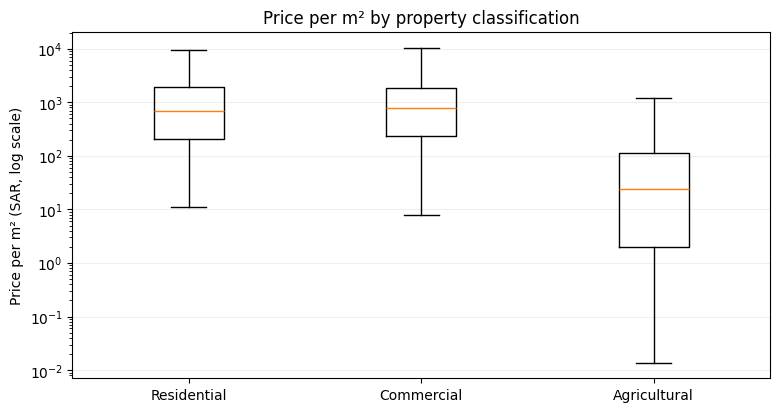

In [ ]:
# Temporary price per m², only for inspecting each classification (not saved in df).
price_per_m2 = df['Price'] / df['Area']

# Spread of price per m² in each classification.
summary = price_per_m2.groupby(df['Classification']).describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
display(summary.round(1))

# Box plot on a log scale: each box shows the middle 50% of prices per classification.
fig, ax = plt.subplots(figsize=(9, 4.5))
groups = ['سكني', 'تجاري', 'زراعي']
english = ['Residential', 'Commercial', 'Agricultural']
ax.boxplot([price_per_m2[df['Classification'] == g] for g in groups],
           tick_labels=english, showfliers=False, whis=(1, 99))
ax.set_yscale('log')
ax.set_ylabel('Price per m² (SAR, log scale)')
ax.set_title('Price per m² by property classification')
ax.grid(axis='y', alpha=0.2)
plt.show()

We remove two classifications and focus the study on **urban real estate** (Residential and Commercial):

* `سكني تجاري` (Residential-Commercial) appears in only 2 of about 1.29 million transactions. That is too few for any model to learn from.
* `زراعي` (Agricultural) is about 3.7% of the transactions. Its price per m² is much lower and far more widely spread than residential and commercial land, as the table and box plot show. Farmland prices depend on factors not in this dataset (water, use, distance from cities), so it is a different market from urban land.

In [ ]:
# Keep only the two urban classifications: residential and commercial.
df = df.loc[df['Classification'].isin(['سكني', 'تجاري'])].copy()

print('Transactions remaining:', len(df))
display(df['Classification'].value_counts().rename('Transactions after removal'))

Transactions remaining: 1243119


,Transactions after removal
Classification,
سكني,1112767
تجاري,130352


# Attribute Construction

## 7. Add a time attribute

`Source_Quarter` (e.g. `2026_Q2`) marks when the transaction happened. A quarter only has meaning together with its year, so we combine them into one number:
`Time = Year + (Quarter − 1) / 4` (e.g. 2026 Q2 → 2026.25). This lets the model learn the price trend over time.

In [ ]:
# Combine year and quarter from the file name into one time value, e.g. '2026_Q2' → 2026.25.
year = df['Source_Quarter'].str[:4].astype(int)
quarter = df['Source_Quarter'].str[-1].astype(int)
df['Time'] = year + (quarter - 1) / 4

# Put the time attributes first, then all the other columns in their current order.
first = ['Source_Quarter', 'Time']
df = df[first + [c for c in df.columns if c not in first]]

display(year.value_counts().sort_index().rename_axis('Year').rename('Transactions per year'))
display(df.head())

,Transactions per year
Year,
2020,268441
2021,266759
2022,207343
2024,240866
2025,195124
2026,64586


,Source_Quarter,Time,Region,City_District,Classification,Num_Properties,Price,Area
0,2020_Q1,2020.0,منطقة مكة المكرمه,الطائف / طيبه,سكني,1,300000.0,835.50
1,2020_Q1,2020.0,منطقة مكة المكرمه,الطائف / الجوديه,سكني,1,54000.0,900.00
2,2020_Q1,2020.0,منطقة مكة المكرمه,الطائف / البوادي,سكني,1,75000.0,677.50
3,2020_Q1,2020.0,منطقة مكة المكرمه,الطائف / الكدي,سكني,1,100000.0,665.14
4,2020_Q1,2020.0,منطقة مكة المكرمه,الطائف / الكدي,سكني,1,100000.0,665.14


## 8. Create the target: price per square meter

`Price_per_m2 = Price / Area` makes properties of different sizes comparable.
`Price` is used only to create the target. It is **not** a predictor, because it would reveal the answer.

In [ ]:
# Create the target attribute.
df['Price_per_m2'] = df['Price'] / df['Area']

# Look at the spread of the target, including the extreme percentiles.
display(df['Price_per_m2'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

,Price_per_m2
count,1243119.00
mean,1658.46
std,101670.67
min,0.00
1%,10.04
5%,33.33
25%,211.64
50%,700.00
75%,1905.86
95%,5000.00


# Data Splitting

## 9. Separate predictors, target and test data

`X` contains the predictors and `y` contains the target `Price_per_m2`.
`Price` is not in `X` because the target is calculated from it. `Source_Quarter` is not in `X` because `Time` carries the same information.

We split **before** handling outliers and encoding, because outlier boundaries and category encodings are learned from data. They must be learned from the **Training Set only** and then reused for the Test Set.
We reserve 20% for testing. `stratify` keeps the share of each property classification similar in both sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Select the predictor attributes and keep the target in a separate variable.
feature_columns = ['Time', 'Region', 'City_District',
                   'Classification', 'Num_Properties', 'Area']
X = df[feature_columns].copy()
y = df['Price_per_m2'].copy()

# Reserve 20% for testing; keep property classification proportions similar.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df['Classification'])

print('Predictors:', len(feature_columns))
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
display(pd.DataFrame({'Training share': X_train['Classification'].value_counts(normalize=True).round(3),
                      'Test share': X_test['Classification'].value_counts(normalize=True).round(3)}))

Predictors: 6
Training rows: 994495 | Test rows: 248624


,Training share,Test share
Classification,,
سكني,0.895,0.895
تجاري,0.105,0.105


# Outlier Handling

## 10. Find unusual prices per m² using the training data

The target ranges from about 0 to 75 million SAR/m², while the median is about 700. Such extreme values are not real market prices: they are nominal transfers (e.g. gifts or inheritance) or data-entry errors.

* Because the values are extremely skewed, we use the **IQR rule on log(price per m²)**: lower boundary Q1 − 1.5 × IQR, upper boundary Q3 + 1.5 × IQR.
* Prices differ strongly between cities and between residential and commercial land, so the boundaries are calculated **for each city and classification** (e.g. Riyadh residential). A sale is judged against what is normal **for its own city**.
* Groups with fewer than 30 training sales are too small for a reliable rule, so they use the **national boundaries of their classification** instead.
* The boundaries are learned from the **Training Set only**.

In [ ]:
MIN_SALES = 30  # minimum training sales for a city-level rule

# City of each sale (part before '/').
train_city = X_train['City_District'].str.split('/').str[0].str.strip()
test_city = X_test['City_District'].str.split('/').str[0].str.strip()
log_y_train = np.log(y_train)

def iqr_limits(groups):
    # Lower and upper limits (log scale) for each group, from TRAINING data only.
    q = log_y_train.groupby(groups).quantile([0.25, 0.75]).unstack()
    iqr = q[0.75] - q[0.25]
    return pd.DataFrame({'Lower': q[0.25] - 1.5 * iqr, 'Upper': q[0.75] + 1.5 * iqr,
                         'Sales': log_y_train.groupby(groups).size()})

city_limits = iqr_limits([train_city, X_train['Classification']])
city_limits = city_limits[city_limits['Sales'] >= MIN_SALES]   # keep only reliable groups
national_limits = iqr_limits(X_train['Classification'])        # fallback: one national rule per classification

def inside_limits(X_part, city, y_part):
    keys = list(zip(city, X_part['Classification']))
    lower = pd.Series([city_limits['Lower'].get(k, np.nan) for k in keys], index=X_part.index)
    upper = pd.Series([city_limits['Upper'].get(k, np.nan) for k in keys], index=X_part.index)
    # Fall back to the national limits where the city group is missing or too small.
    lower = lower.fillna(X_part['Classification'].map(national_limits['Lower']))
    upper = upper.fillna(X_part['Classification'].map(national_limits['Upper']))
    log_y = np.log(y_part)
    return (log_y >= lower) & (log_y <= upper)

keep_train = inside_limits(X_train, train_city, y_train)
keep_test = inside_limits(X_test, test_city, y_test)
print('Groups with their own limits:', len(city_limits))
print(f'Removed: training {(~keep_train).mean():.2%}, test {(~keep_test).mean():.2%}')

Groups with their own limits: 273
Removed: training 2.61%, test 2.60%


**Result:** 273 city and classification groups have their own limits. The rule removes 2.61% of training and 2.60% of test transactions, more than a single national rule, because a price can be normal nationally but unusual for its city.

## 11. Remove the outliers from both sets

We remove the rows outside the boundaries. The **same training boundaries** are applied to the Test Set; no new boundaries are calculated from test data.

In [ ]:
# Keep only rows inside the training boundaries, in both sets.
X_train, y_train = X_train.loc[keep_train].copy(), y_train.loc[keep_train].copy()
X_test, y_test = X_test.loc[keep_test].copy(), y_test.loc[keep_test].copy()

print('Training rows after outlier removal:', len(X_train))
print('Test rows after outlier removal:', len(X_test))
display(y_train.describe().round(3).rename('Training price per m² after cleaning'))

Training rows after outlier removal: 968561
Test rows after outlier removal: 242161


,Training price per m² after cleaning
count,968561.000
mean,1436.420
std,1948.394
min,0.713
25%,225.518
50%,712.322
75%,1920.000
max,33750.000


# Correlation Analysis

## 12. Study the relationships between attributes

Correlation measures how strongly two numeric attributes move together, from −1 (opposite directions) to +1 (same direction).
We calculate it on the **Training Set only**, using a temporary numeric copy of the attributes:

* `Time`: year and quarter as one number (e.g. 2026 Q2 → 2026.25).
* `Num_Properties`: number of properties in the transaction.
* `Log_Area` and `Log_Price_per_m2`: area and price per m² on a log scale, because both are very skewed.
* `Is_Commercial`: the property classification as one 0/1 column, **1 = Commercial, 0 = Residential**. A positive correlation means the attribute tends to be higher for commercial properties.
* `Region_...`: one yes/no column per region (1 = the property is in that region). `City_District` is left out because it has almost 10,000 values.

Pairs of two regions are ignored: they are always negatively related because a property belongs to only one region.

In [ ]:
# Temporary numeric copy of the TRAINING data, only for correlation.
corr_data = pd.DataFrame({
    'Time': X_train['Time'],
    'Num_Properties': X_train['Num_Properties'],
    'Log_Area': np.log(X_train['Area']),
    'Is_Commercial': (X_train['Classification'] == 'تجاري').astype(int),
    'Log_Price_per_m2': np.log(y_train)})
region_columns = pd.get_dummies(X_train['Region'], prefix='Region', dtype=int)
corr_data = pd.concat([corr_data, region_columns], axis=1)

# Pearson correlation between every pair of attributes.
corr = corr_data.corr()

# List every pair once, skipping self-pairs and region-vs-region pairs.
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[~(pairs.index.get_level_values(0).str.startswith('Region_') &
                pairs.index.get_level_values(1).str.startswith('Region_'))]

print('Highest positive correlation:', pairs.idxmax(), round(pairs.max(), 3))
print('Highest negative correlation:', pairs.idxmin(), round(pairs.min(), 3))

# Correlation of each attribute with the target, for context.
display(corr['Log_Price_per_m2'].drop('Log_Price_per_m2').sort_values().round(3)
        .rename('Correlation with log(price per m²)'))

Highest positive correlation: ('Log_Area', 'Is_Commercial') 0.224
Highest negative correlation: ('Log_Area', 'Log_Price_per_m2') -0.381


,Correlation with log(price per m²)
Log_Area,-0.381
Region_منطقة الحدود الشمالية,-0.175
Region_منطقة حائل,-0.170
Region_منطقة القصيم,-0.162
Region_منطقة نجران,-0.159
Region_منطقة الجوف,-0.126
Region_منطقة عسير,-0.115
Region_منطقة جازان,-0.076
Region_منطقة الباحة,-0.075
Region_منطقة تبوك,-0.034


**Results:**
* **Highest positive correlation: `Log_Area` and `Is_Commercial` (+0.224).** Commercial properties tend to be larger than residential ones.
* **Highest negative correlation: `Log_Area` and `Log_Price_per_m2` (−0.381).** Larger plots sell for less per m². They are typically raw land on city outskirts, while smaller plots lie in developed districts.

Other relationships with the target:
* `Time` (+0.194): prices per m² increased over 2020–2026.
* Regions: Makkah (+0.202) and Riyadh (+0.180) are the most expensive regions; Northern Borders (−0.175), Hail (−0.170) and Qassim (−0.162) are the cheapest.
* `Is_Commercial` (+0.010) and `Num_Properties` (+0.029) have almost no direct linear relationship with the price per m².

# Encoding

## 13. Encode the attributes for the models

The models need numeric inputs. Everything that is learned here is learned from the **Training Set only** and then reused for the Test Set.

| Attribute | Encoding |
|---|---|
| `Classification` | 0/1: **1 = Commercial, 0 = Residential** |
| `Region` (13 values) | one-hot: one yes/no column per region |
| `City_District` (~10,000 values) | **target encoding** → `District_Price` |
| `City` (165 values, taken from `City_District`) | **target encoding** → `City_Price` |
| `Area` | log scale → `Log_Area`, because it is very skewed |

**Target encoding** replaces each district (or city) with the typical log(price per m²) of that location in the training data, a single number saying "how expensive this location usually is". One-hot encoding would create about 10,000 columns.
To avoid learning from a row's own answer, scikit-learn's `TargetEncoder` uses:
* **Smoothing:** districts with few sales are pulled toward the overall average.
* **Cross-fitting (5 folds):** each training row is encoded using the other folds, not itself.

`District_Price`, `City_Price` and `Region` give the model location information at three levels of detail. When a district has few or no training sales, the model can rely on the city and region levels.

In [ ]:
import sklearn

# Take the city from the part before '/' (verified earlier to match the original city column).
for table in [X_train, X_test]:
    table['City'] = table['City_District'].str.split('/').str[0].str.strip()

print('Cities in training data:', X_train['City'].nunique())
print('Districts in training data:', X_train['City_District'].nunique())

Cities in training data: 164
Districts in training data: 9567


In [ ]:
from sklearn.preprocessing import TargetEncoder

# Learn the typical log(price per m²) of each district and city from TRAINING data only.
target_encoder = TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=42)
location_columns = ['City_District', 'City']

# fit_transform uses cross-fitting on the training rows; transform reuses the training values on the test rows.
train_locations = target_encoder.fit_transform(X_train[location_columns], np.log(y_train))
test_locations = target_encoder.transform(X_test[location_columns])

X_train[['District_Price', 'City_Price']] = train_locations
X_test[['District_Price', 'City_Price']] = test_locations

# Districts in the test set that never appeared in training (they receive the overall average).
unseen = ~X_test['City_District'].isin(X_train['City_District'])
print('Test rows with a district not seen in training:', unseen.sum(),
      f'({100 * unseen.mean():.2f}% of test rows)')
display(X_train[['City_District', 'District_Price', 'City', 'City_Price']].head())

Test rows with a district not seen in training: 595 (0.25% of test rows)


,City_District,District_Price,City,City_Price
885457,الرياض / لبن,7.768045,الرياض,7.345564
556836,الرياض / شرق الرياض,5.741769,الرياض,7.345343
996749,الرياض / النظيم,7.113842,الرياض,7.345787
551882,الرياض / العلا,5.594831,الرياض,7.344601
36516,الرياض / الرابيه,6.060587,الرياض,7.345343


Only 595 test transactions (0.25%) are in a district that never appeared in training, so almost every test property has a learned district price.

In [ ]:
def encode_remaining(table):
    # Fixed rules (not learned from data): classification as 0/1 and area on a log scale.
    ready = table.copy()
    ready['Is_Commercial'] = (ready['Classification'] == 'تجاري').astype(int)
    ready['Log_Area'] = np.log(ready['Area'])
    return ready

X_train_ready = encode_remaining(X_train)
X_test_ready = encode_remaining(X_test)

# One-hot encode Region; the test set gets exactly the same columns as training.
train_regions = pd.get_dummies(X_train_ready['Region'], prefix='Region', dtype=int)
test_regions = pd.get_dummies(X_test_ready['Region'], prefix='Region', dtype=int)
test_regions = test_regions.reindex(columns=train_regions.columns, fill_value=0)

# Keep only numeric model inputs.
model_columns = ['Time', 'Num_Properties', 'Log_Area', 'Is_Commercial', 'District_Price', 'City_Price']
X_train_ready = pd.concat([X_train_ready[model_columns], train_regions], axis=1)
X_test_ready = pd.concat([X_test_ready[model_columns], test_regions], axis=1)

# The models learn log(price per m²); predictions are converted back to SAR/m² for evaluation.
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

assert not X_train_ready.isna().any().any() and not X_test_ready.isna().any().any()
print('Model inputs:', X_train_ready.shape[1], 'columns')
print('Training:', X_train_ready.shape, '| Test:', X_test_ready.shape)
display(X_train_ready.head())

Model inputs: 19 columns
Training: (968561, 19) | Test: (242161, 19)


,Time,Num_Properties,Log_Area,Is_Commercial,District_Price,City_Price,Region_منطقة الباحة,Region_منطقة الجوف,Region_منطقة الحدود الشمالية,Region_منطقة الرياض,Region_منطقة الشرقية,Region_منطقة القصيم,Region_منطقة المدينة المنوره,Region_منطقة تبوك,Region_منطقة جازان,Region_منطقة حائل,Region_منطقة عسير,Region_منطقة مكة المكرمه,Region_منطقة نجران
885457,2024.50,2,7.783224,1,7.768045,7.345564,0,0,0,1,0,0,0,0,0,0,0,0,0
556836,2021.75,1,6.833032,0,5.741769,7.345343,0,0,0,1,0,0,0,0,0,0,0,0,0
996749,2024.75,1,4.641213,0,7.113842,7.345787,0,0,0,1,0,0,0,0,0,0,0,0,0
551882,2021.75,1,6.802395,0,5.594831,7.344601,0,0,0,1,0,0,0,0,0,0,0,0,0
36516,2020.00,1,6.068426,0,6.060587,7.345343,0,0,0,1,0,0,0,0,0,0,0,0,0


# Normalization

## 14. Z-score normalization for Linear Regression and the Neural Network

The inputs have very different ranges: `Time` is about 2,020, while `Is_Commercial` is 0 or 1. Linear Regression and the Neural Network are sensitive to this, so we rescale every input to mean 0 and standard deviation 1:
`(value − training_mean) / training_std`

The mean and standard deviation are learned from the **Training Set only** and reused for the Test Set.
**The Decision Tree does not need scaling** (it only compares a value with a threshold), so it uses the unscaled inputs.

In [ ]:
# Learn the mean and standard deviation from TRAINING inputs only.
training_mean = X_train_ready.mean()
training_std = X_train_ready.std().replace(0, 1)  # Avoid division by zero.

# Apply exactly the same scale to training and test inputs.
X_train_scaled = (X_train_ready - training_mean) / training_std
X_test_scaled = (X_test_ready - training_mean) / training_std

display(X_train_scaled.head())

,Time,Num_Properties,Log_Area,Is_Commercial,District_Price,City_Price,Region_منطقة الباحة,Region_منطقة الجوف,Region_منطقة الحدود الشمالية,Region_منطقة الرياض,Region_منطقة الشرقية,Region_منطقة القصيم,Region_منطقة المدينة المنوره,Region_منطقة تبوك,Region_منطقة جازان,Region_منطقة حائل,Region_منطقة عسير,Region_منطقة مكة المكرمه,Region_منطقة نجران
885457,0.871491,1.607587,2.227202,2.933755,1.035086,0.824026,-0.080226,-0.141431,-0.134718,1.458673,-0.40711,-0.30115,-0.222098,-0.149946,-0.153263,-0.204057,-0.231661,-0.517142,-0.132528
556836,-0.517421,-0.058517,0.893822,-0.340860,-0.519488,0.823830,-0.080226,-0.141431,-0.134718,1.458673,-0.40711,-0.30115,-0.222098,-0.149946,-0.153263,-0.204057,-0.231661,-0.517142,-0.132528
996749,0.997756,-0.058517,-2.181901,-0.340860,0.533176,0.824224,-0.080226,-0.141431,-0.134718,1.458673,-0.40711,-0.30115,-0.222098,-0.149946,-0.153263,-0.204057,-0.231661,-0.517142,-0.132528
551882,-0.517421,-0.058517,0.850830,-0.340860,-0.632220,0.823172,-0.080226,-0.141431,-0.134718,1.458673,-0.40711,-0.30115,-0.222098,-0.149946,-0.153263,-0.204057,-0.231661,-0.517142,-0.132528
36516,-1.401275,-0.058517,-0.179130,-0.340860,-0.274889,0.823830,-0.080226,-0.141431,-0.134718,1.458673,-0.40711,-0.30115,-0.222098,-0.149946,-0.153263,-0.204057,-0.231661,-0.517142,-0.132528


## 15. Training sample (for development)

While building and debugging the models, we train on a random sample of the training set so each run takes seconds instead of minutes.
For the final results, `SAMPLE_SIZE` is set to `None` to use the full training set. The test set is always used in full.

In [ ]:
SAMPLE_SIZE = None  # Set to None for the final run on the full training set.

if SAMPLE_SIZE is None:
    sample_index = X_train_ready.index
else:
    sample_index = X_train_ready.sample(n=SAMPLE_SIZE, random_state=42).index

# The SAME rows in every version of the training data.
X_fit = X_train_ready.loc[sample_index]          # unscaled, for the Decision Tree
X_fit_scaled = X_train_scaled.loc[sample_index]  # scaled, for Linear Regression and the Neural Network
y_fit_log = y_train_log.loc[sample_index]        # target on the log scale

print('Training rows used:', len(X_fit), '| Test rows:', len(X_test_ready))

Training rows used: 968561 | Test rows: 242161


# Task A: Regression (predict price per m²)

## 16. How the regression models are evaluated

The models learn **log(price per m²)**, because the target is very skewed. Their predictions are converted back to SAR/m² with `exp()` before calculating the errors, so the errors are in real units.

| Metric | What it tells us |
|---|---|
| MAE | Average absolute error in SAR/m²: on average, how far the prediction is from the real price. Lower is better. |
| RMSE | Like MAE, but large errors count more. Lower is better. |
| R² | Share of the variation in price per m² that the model explains: 1 = perfect, 0 = no better than always predicting the average. Higher is better. |
| R² (log) | The same, measured on the log scale the models learn on. |

We evaluate each model on the **training rows it learned from** and on the **test set**. A large gap between them suggests overfitting.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_scores(name, model, X_tr, X_te):
    # Predict on the log scale, then convert back to SAR/m².
    rows = []
    for split, X_part, y_log in [('Training', X_tr, y_fit_log), ('Test', X_te, y_test_log)]:
        pred_log = model.predict(X_part)
        actual, predicted = np.exp(y_log), np.exp(pred_log)
        rows.append({'Model': name, 'Set': split,
                     'MAE (SAR/m²)': mean_absolute_error(actual, predicted),
                     'RMSE (SAR/m²)': np.sqrt(mean_squared_error(actual, predicted)),
                     'R²': r2_score(actual, predicted),
                     'R² (log)': r2_score(y_log, pred_log)})
    return rows

regression_results = []  # Each model adds its rows here.

## 17. Baseline: Linear Regression

Linear Regression learns one weight per input and predicts a weighted sum. It is a simple baseline: it can only learn straight-line relationships. It uses the **scaled** inputs.

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_fit_scaled, y_fit_log)

regression_results += regression_scores('Linear Regression', linear_model, X_fit_scaled, X_test_scaled)
display(pd.DataFrame(regression_results).round(3))

,Model,Set,MAE (SAR/m²),RMSE (SAR/m²),R²,R² (log)
0,Linear Regression,Training,547.284,1188.025,0.628,0.792
1,Linear Regression,Test,546.127,1177.510,0.633,0.792


## 18. Baseline: Decision Tree Regressor

The tree learns a sequence of yes/no questions (e.g. "is District_Price > 6.8?") and predicts the average log price of the training rows in each final leaf. It uses the **unscaled** inputs.
`max_depth` and `min_samples_leaf` limit the tree's growth (**pre-pruning**) to reduce overfitting. These are starting values; they are tuned later.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42)
tree_model.fit(X_fit, y_fit_log)  # Unscaled inputs

regression_results += regression_scores('Decision Tree', tree_model, X_fit, X_test_ready)
display(pd.DataFrame(regression_results).round(3))

,Model,Set,MAE (SAR/m²),RMSE (SAR/m²),R²,R² (log)
0,Linear Regression,Training,547.284,1188.025,0.628,0.792
1,Linear Regression,Test,546.127,1177.510,0.633,0.792
2,Decision Tree,Training,471.466,1036.792,0.717,0.826
3,Decision Tree,Test,478.146,1049.845,0.708,0.819


## 19. Baseline: Neural Network (Multi-Layer Perceptron)

The network has two hidden layers (64 and 32 neurons) with the ReLU activation, and learns its weights by backpropagation. It uses the **scaled** inputs.
`early_stopping=True` keeps 10% of the training rows aside and stops training when the error on them stops improving, which reduces overfitting. These are starting values; they are tuned later.

In [ ]:
from sklearn.neural_network import MLPRegressor

nn_model = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                        early_stopping=True, max_iter=200, random_state=42)
nn_model.fit(X_fit_scaled, y_fit_log)  # Scaled inputs
print('Training stopped after', nn_model.n_iter_, 'iterations')

regression_results += regression_scores('Neural Network', nn_model, X_fit_scaled, X_test_scaled)
display(pd.DataFrame(regression_results).round(3))

Training stopped after 51 iterations


,Model,Set,MAE (SAR/m²),RMSE (SAR/m²),R²,R² (log)
0,Linear Regression,Training,547.284,1188.025,0.628,0.792
1,Linear Regression,Test,546.127,1177.510,0.633,0.792
2,Decision Tree,Training,471.466,1036.792,0.717,0.826
3,Decision Tree,Test,478.146,1049.845,0.708,0.819
4,Neural Network,Training,496.163,1096.013,0.684,0.817
5,Neural Network,Test,495.398,1086.088,0.687,0.816


### Testing errors by price level before tuning:

In [ ]:
actual = np.exp(y_test_log.values)
models = {'Linear Regression': (linear_model, X_test_scaled),
          'Decision Tree': (tree_model, X_test_ready),
          'Neural Network': (nn_model, X_test_scaled)}
band = pd.qcut(actual, 5, labels=['Lowest 20%', '20-40%', '40-60%', '60-80%', 'Highest 20%'])

rows = []
for name, (m, X_te) in models.items():
    err = np.abs(np.exp(m.predict(X_te)) - actual)
    rows.append({'Model': name, 'MAE': err.mean(), 'Median abs error': np.median(err),
                 'Median % error': 100 * np.median(err / actual)})
display(pd.DataFrame(rows).round(1))

# Typical error by price level: this is what "error on a 400 m² house" should be based on.
display(pd.DataFrame({n: np.abs(np.exp(m.predict(X)) - actual) for n, (m, X) in models.items()})
        .groupby(band, observed=True).median().round(0))

,Model,MAE,Median abs error,Median % error
0,Linear Regression,546.1,189.8,32.6
1,Decision Tree,478.1,162.0,27.7
2,Neural Network,495.4,171.9,28.9


,Linear Regression,Decision Tree,Neural Network
Lowest 20%,43.0,35.0,36.0
20-40%,97.0,85.0,87.0
40-60%,195.0,175.0,184.0
60-80%,393.0,349.0,369.0
Highest 20%,1144.0,882.0,936.0


## 20. Tune the Decision Tree

The settings in section 18 were starting values. To choose better ones, we try several combinations and keep the best, using **cross-validation** on a fixed sample of 100,000 training rows (so tuning takes the same time whatever `SAMPLE_SIZE` is):

- The sample is split into 3 parts. The model trains on 2 parts and is scored on the third, three times.
- The score is the **negative MAE on the log scale**: the closer to 0, the better.
- The Test Set is **not** used, so the final test results stay honest.
- `GridSearchCV` tries every combination of `max_depth` (how deep the tree can grow) and `min_samples_leaf` (the minimum rows in a final leaf). A deeper tree fits more detail; a larger leaf makes it more cautious.

`RUN_TUNING` can be set to `False` to skip the searches; the best settings are then taken from section 22.

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

RUN_TUNING = True  # Set to False to skip the searches (the best settings are written in section 22).

# A fixed sample of 100,000 training rows, used only for tuning.
tune_index = X_train_ready.sample(n=100_000, random_state=42).index
X_tune = X_train_ready.loc[tune_index]          # unscaled, for the Decision Tree
X_tune_scaled = X_train_scaled.loc[tune_index]  # scaled, for the Neural Network
y_tune_log = y_train_log.loc[tune_index]

if RUN_TUNING:
    # Try all 20 combinations, each scored with 3-fold cross-validation.
    tree_search = GridSearchCV(
        DecisionTreeRegressor(random_state=42),
        param_grid={'max_depth': [8, 10, 12, 15, 20],
                    'min_samples_leaf': [10, 20, 50, 100]},
        cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
    tree_search.fit(X_tune, y_tune_log)

    print('Best Decision Tree settings:', tree_search.best_params_)
    print('Best score (negative MAE, log scale):', round(tree_search.best_score_, 4))
    results = pd.DataFrame(tree_search.cv_results_)
    display(results[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score']]
            .sort_values('mean_test_score', ascending=False).head(8).round(4))

Best Decision Tree settings: {'max_depth': 20, 'min_samples_leaf': 50}
Best score (negative MAE, log scale): -0.4527


,param_max_depth,param_min_samples_leaf,mean_test_score
18,20,50,-0.4527
14,15,50,-0.4528
10,12,50,-0.4536
9,12,20,-0.4537
13,15,20,-0.4541
19,20,100,-0.4546
15,15,100,-0.4546
8,12,10,-0.4551


## 21. Tune the Neural Network

The network in section 19 used default settings. We try other combinations to see whether a different size or regularization improves it:

- `hidden_layer_sizes`: a larger network can learn more complex patterns.
- `alpha`: the strength of regularization. Smaller values let the network fit the data more closely.
- `batch_size`: how many rows are used for each weight update.

There are 18 combinations, so `RandomizedSearchCV` tries 6 random ones to save time. It uses the same 3-fold cross-validation on the same 100,000-row sample, so the Test Set is not used.



In [ ]:
if RUN_TUNING:
    nn_search = RandomizedSearchCV(
        MLPRegressor(activation='relu', early_stopping=True, max_iter=200,
                     n_iter_no_change=15, random_state=42),
        param_distributions={'hidden_layer_sizes': [(64, 32), (128, 64), (128, 64, 32)],
                             'alpha': [1e-5, 1e-4, 1e-3],
                             'batch_size': [256, 512]},
        n_iter=6, cv=3, scoring='neg_mean_absolute_error', random_state=42, n_jobs=1)
    nn_search.fit(X_tune_scaled, y_tune_log)

    print('Best Neural Network settings:', nn_search.best_params_)
    print('Best score (negative MAE, log scale):', round(nn_search.best_score_, 4))
    results = pd.DataFrame(nn_search.cv_results_)
    display(results[['param_hidden_layer_sizes', 'param_alpha', 'param_batch_size', 'mean_test_score']]
            .sort_values('mean_test_score', ascending=False).round(4))

Best Neural Network settings: {'hidden_layer_sizes': (128, 64, 32), 'batch_size': 256, 'alpha': 0.0001}
Best score (negative MAE, log scale): -0.4558


,param_hidden_layer_sizes,param_alpha,param_batch_size,mean_test_score
2,"(128, 64, 32)",0.0001,256,-0.4558
1,"(128, 64)",0.0000,256,-0.4561
3,"(128, 64, 32)",0.0000,512,-0.4569
5,"(128, 64)",0.0010,256,-0.4573
0,"(64, 32)",0.0000,256,-0.4581
4,"(64, 32)",0.0000,512,-0.4592


# Final Regression Models

## 22. Final regression models

We train the three models again with the best settings from sections 20 and 21, and evaluate them on the Test Set:

| Model | Settings | Inputs |
|---|---|---|
| Linear Regression | nothing to tune | scaled |
| Decision Tree | `max_depth=20`, `min_samples_leaf=50` | unscaled |
| Neural Network | layers (128, 64, 32), `alpha=1e-4`, `batch_size=256` | scaled |

The training rows are the ones chosen in section 15: `SAMPLE_SIZE = None` means the **full training set** (the setting used for the final results), while 100,000 rows is the quick setting used during development.

Besides MAE, RMSE and R², we add two measures of the *typical* miss, because MAE is pulled up by a few expensive properties:

- **Median error**: half of the test properties are predicted with a smaller error than this.
- **Median % error**: the same, relative to the real price.

The `else` options in the code hold the best settings found in sections 20 and 21, so this section also runs when the searches are skipped (`RUN_TUNING = False`).

In [ ]:
import time

# Best settings from sections 20-21 (used when the searches are skipped with RUN_TUNING = False).
best_tree_params = tree_search.best_params_ if RUN_TUNING else {'max_depth': 20, 'min_samples_leaf': 50}
best_nn_params = nn_search.best_params_ if RUN_TUNING else {'hidden_layer_sizes': (128, 64, 32), 'alpha': 1e-4, 'batch_size': 256}

def full_scores(name, model, X_tr, X_te):
    # Scores in SAR/m² on the rows the model learned from and on the test set.
    rows = []
    for split, X_part, y_log in [('Training', X_tr, y_fit_log), ('Test', X_te, y_test_log)]:
        pred_log = model.predict(X_part)
        actual, predicted = np.exp(y_log), np.exp(pred_log)
        error = np.abs(predicted - actual)
        rows.append({'Model': name, 'Set': split,
                     'MAE (SAR/m²)': error.mean(),
                     'RMSE (SAR/m²)': np.sqrt(mean_squared_error(actual, predicted)),
                     'Median error (SAR/m²)': np.median(error),
                     'Median % error': 100 * np.median(error / actual),
                     'R²': r2_score(actual, predicted),
                     'R² (log)': r2_score(y_log, pred_log)})
    return rows

# model, training inputs, test inputs
final_models = {
    'Linear Regression': (LinearRegression(), X_fit_scaled, X_test_scaled),
    'Decision Tree': (DecisionTreeRegressor(random_state=42, **best_tree_params), X_fit, X_test_ready),
    'Neural Network': (MLPRegressor(activation='relu', early_stopping=True, max_iter=200,
                                    n_iter_no_change=15, random_state=42, **best_nn_params),
                       X_fit_scaled, X_test_scaled)}

final_results = []
for name, (model, X_tr, X_te) in final_models.items():
    print(f'Training {name} on {len(X_tr):,} rows... (please wait, do not stop the cell)')
    start = time.time()
    model.fit(X_tr, y_fit_log)  # learn from the training rows only
    final_results += full_scores(name, model, X_tr, X_te)
    print(f'{name}: trained in {time.time() - start:.0f} seconds')

display(pd.DataFrame(final_results).round(3))

Training Linear Regression on 968,561 rows... (please wait, do not stop the cell)
Linear Regression: trained in 1 seconds
Training Decision Tree on 968,561 rows... (please wait, do not stop the cell)
Decision Tree: trained in 8 seconds
Training Neural Network on 968,561 rows... (please wait, do not stop the cell)
Neural Network: trained in 4306 seconds


,Model,Set,MAE (SAR/m²),RMSE (SAR/m²),Median error (SAR/m²),Median % error,R²,R² (log)
0,Linear Regression,Training,547.284,1188.025,189.297,32.526,0.628,0.792
1,Linear Regression,Test,546.127,1177.510,189.799,32.641,0.633,0.792
2,Decision Tree,Training,441.768,999.671,142.072,24.860,0.737,0.840
3,Decision Tree,Test,460.033,1027.969,147.532,25.658,0.720,0.825
4,Neural Network,Training,478.174,1062.622,160.943,27.349,0.703,0.828
5,Neural Network,Test,479.161,1056.636,162.634,27.425,0.704,0.824


**Results (test set):**
* **The Decision Tree is the best model:** MAE 460 SAR/m², median error 26%, R² (log) 0.825. Its training and test scores are close (R² log 0.840 vs 0.825), so it is not seriously overfitting.
* **Neural Network:** MAE 479, median error 27%, R² (log) 0.824.
* **Linear Regression** is the weakest (MAE 546, median error 33%, R² log 0.792), because it can only learn straight-line relationships.
* **Tuning improved both models:** Decision Tree test MAE 478 → 460, Neural Network 495 → 479. The settings tried scored close to each other in cross-validation (Decision Tree about −0.453 to −0.455, Neural Network −0.456 to −0.459), so the remaining error comes mostly from information missing in the data (street, plot shape, buildings), not from the model settings.

## 23. Typical error by price level after tuning

The error grows with the price level, so a single number hides where the models struggle. We sort the test properties by their real price per m², split them into five equal groups, and show the **median error** of each model in each group (SAR/m²). The first column shows the median real price of the group, to put the errors in context.

In [ ]:
actual = np.exp(y_test_log.values)  # real test prices in SAR/m²
band = pd.qcut(actual, 5, labels=['Lowest 20%', '20-40%', '40-60%', '60-80%', 'Highest 20%'])

errors = pd.DataFrame({name: np.abs(np.exp(model.predict(X_te)) - actual)
                       for name, (model, X_tr, X_te) in final_models.items()})
by_level = errors.groupby(band, observed=True).median()
by_level.insert(0, 'Median real price', pd.Series(actual).groupby(band, observed=True).median())
display(by_level.round(0))

,Median real price,Linear Regression,Decision Tree,Neural Network
Lowest 20%,83.0,43.0,34.0,33.0
20-40%,300.0,97.0,79.0,83.0
40-60%,714.0,195.0,155.0,178.0
60-80%,1567.0,393.0,317.0,355.0
Highest 20%,3680.0,1144.0,825.0,860.0


**Results:** errors in SAR/m² grow with the price level, but relative to the price they are smallest for mid- and high-priced properties (about 20–22% for the Decision Tree) and largest for the cheapest 20% (about 41%), which are often remote or unusual sales. The Decision Tree has the smallest error in every group except the cheapest, where the Neural Network is about equal (33 vs 34 SAR/m²); the tree's advantage is largest for the most expensive properties (825 vs 1,144 SAR/m² for Linear Regression).

## 24. Plots for the paper: predictions and important inputs

Two plots for the Decision Tree, the best regression model:

- **Left: predicted vs real price per m²** for 5,000 random test properties (both axes on a log scale). Points on the red line are perfect predictions; the wider the cloud around the line, the larger the error.
- **Right: which inputs the tree relies on.** The importance of an input is its share of the tree's total error reduction. The 13 region columns are added together.

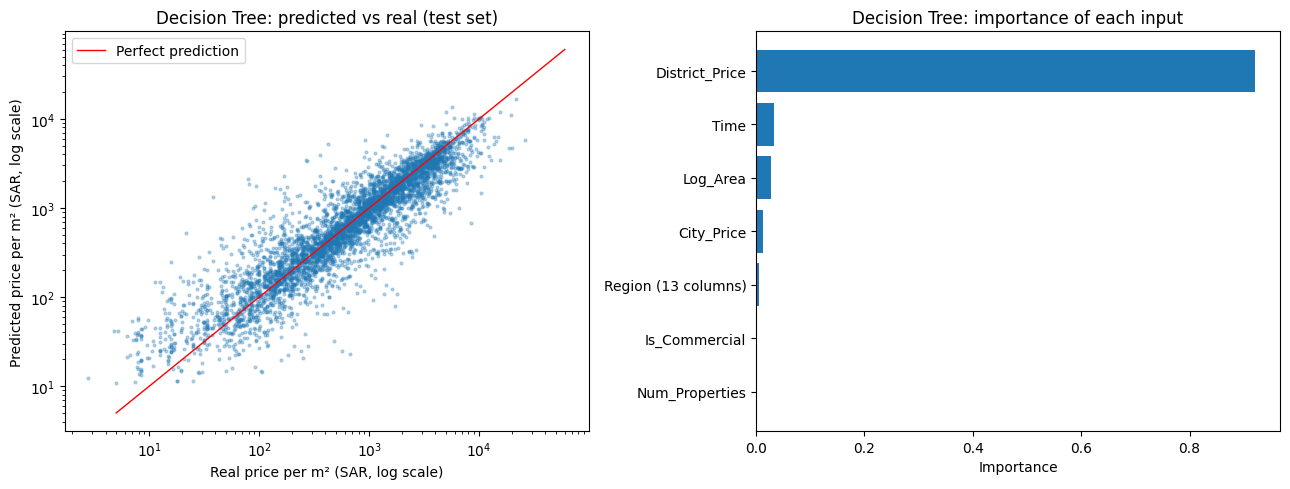

In [ ]:
tree_final, _, X_tree_test = final_models['Decision Tree']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: predicted vs real price per m² on a random subset of the test set.
shown = np.random.RandomState(42).choice(len(X_tree_test), size=min(5000, len(X_tree_test)), replace=False)
real = np.exp(y_test_log.values[shown])
predicted = np.exp(tree_final.predict(X_tree_test.iloc[shown]))
axes[0].scatter(real, predicted, s=4, alpha=0.3)
axes[0].plot([5, 60000], [5, 60000], color='red', lw=1, label='Perfect prediction')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Real price per m² (SAR, log scale)')
axes[0].set_ylabel('Predicted price per m² (SAR, log scale)')
axes[0].set_title('Decision Tree: predicted vs real (test set)')
axes[0].legend()

# Right: importance of each input (the 13 region columns are added together).
importance = pd.Series(tree_final.feature_importances_, index=X_tree_test.columns)
region_total = importance[importance.index.str.startswith('Region_')].sum()
importance = importance[~importance.index.str.startswith('Region_')]
importance['Region (13 columns)'] = region_total
importance = importance.sort_values()
axes[1].barh(importance.index, importance.values)
axes[1].set_xlabel('Importance')
axes[1].set_title('Decision Tree: importance of each input')

plt.tight_layout()
plt.show()

**Results:**
* **Predicted vs real (left):** most points lie close to the red line across the whole price range, so the tree captures the general price level well. The cloud is wider for cheap properties (below about 100 SAR/m²), matching the larger percentage errors in section 23. The predictions are also pulled toward the middle: very cheap properties tend to be over-predicted and very expensive ones under-predicted, because the tree predicts the average of similar training sales.
* **Importance of each input (right):** `District_Price` dominates with an importance of about **0.9**: the district is by far the strongest predictor of the price per m². `Time` (≈0.05), `Log_Area` (≈0.04) and `City_Price` (≈0.03) add a little extra information. `Region`, `Is_Commercial` and `Num_Properties` contribute almost nothing once the district is known.

# Task B: Classification (predict the price category)

## 25. Create the price categories

Classification predicts a **category** instead of an exact number. We cut the price per m² into three equal-sized groups:

- **Low**: the cheapest third of the training properties.
- **Medium**: the middle third.
- **High**: the most expensive third.

The two cut points are the 33rd and 67th percentiles of the **Training Set** and are reused unchanged for the Test Set. Equal-sized groups mean no category dominates, so a model cannot score well by always guessing the same one.

We also check how Residential and Commercial properties are spread over the categories, to make sure the categories are not just a copy of the property classification.

In [ ]:
# Cut points learned from the TRAINING set only: the 33rd and 67th percentiles of price per m².
low_cut, high_cut = y_train.quantile([1 / 3, 2 / 3])
class_names = ['Low', 'Medium', 'High']

def to_class(prices):
    # Low: up to low_cut | Medium: between the two cut points | High: above high_cut.
    return pd.cut(prices, bins=[-np.inf, low_cut, high_cut, np.inf], labels=class_names).astype(str)

y_train_class = to_class(y_train)
y_test_class = to_class(y_test)

# The price range of each category.
display(pd.DataFrame({'Price per m² (SAR)': [f'up to {low_cut:,.0f}',
                                             f'{low_cut:,.0f} to {high_cut:,.0f}',
                                             f'above {high_cut:,.0f}']}, index=class_names))

# Share of each category in the training and test sets.
display(pd.DataFrame({'Training share (%)': y_train_class.value_counts(normalize=True) * 100,
                      'Test share (%)': y_test_class.value_counts(normalize=True) * 100}).loc[class_names].round(1))

# Residential / Commercial mix inside each category (each row adds up to 100%).
property_type = X_train['Classification'].map({'سكني': 'Residential', 'تجاري': 'Commercial'})
display((pd.crosstab(y_train_class, property_type, normalize='index') * 100).loc[class_names].round(1))

,Price per m² (SAR)
Low,up to 348
Medium,"348 to 1,360"
High,"above 1,360"


,Training share (%),Test share (%)
Price_per_m2,,
Low,33.3,33.2
Medium,33.4,33.3
High,33.3,33.5


Classification,Commercial,Residential
Price_per_m2,,
Low,9.4,90.6
Medium,11.1,88.9
High,10.7,89.3


**Result:** the cut points are 348 and 1,360 SAR/m², and each category holds about one third of the training and test properties. Commercial properties make up about 9–11% of every category, so the categories are not a copy of the property classification.

## 26. How the classification models are evaluated

| Metric | What it tells us | Better |
|---|---|---|
| Accuracy | Share of properties placed in the correct category. | Higher |
| Precision | Of the properties predicted as a category, the share that really belong to it. | Higher |
| Recall | Of the properties that really belong to a category, the share the model finds. | Higher |
| F1 | Combines precision and recall into one number (their harmonic mean). | Higher |
| **Macro-F1** | The average F1 of the three categories, each counting equally. **Our main metric.** | Higher |

Because the three categories have equal sizes, an average weighted by category size gives the same result as the Macro-F1, so we do not report it separately. (The classification reports in section 30 still print a `weighted avg` line automatically; it equals the `macro avg` line.)

The **confusion matrix** shows, for each real category (rows), how often the model predicted each category (columns). Mistakes between neighbouring categories (Low and Medium) are less serious than mistakes between Low and High.

As for regression, we show the scores on the training rows and on the test set: a much better training score means overfitting.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# The categories of the training rows chosen in section 15 (the same rows as X_fit).
y_fit_class = y_train_class.loc[sample_index]

def classification_scores(name, model, X_tr, y_tr, X_te):
    rows = []
    for split, X_part, y_true in [('Training', X_tr, y_tr), ('Test', X_te, y_test_class)]:
        predicted = model.predict(X_part)
        rows.append({'Model': name, 'Set': split,
                     'Accuracy': accuracy_score(y_true, predicted),
                     'Macro-F1': f1_score(y_true, predicted, average='macro')})
    return rows

classification_results = []  # Each model adds its rows here.

## 27. Baseline: always predict the most common category

A baseline shows what a model with no skill would score. This one ignores all inputs and always predicts the most frequent category. With three equal-sized categories we expect an accuracy around 0.33 and a Macro-F1 around 0.17. A real model must clearly beat these numbers.

In [ ]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_fit, y_fit_class)

classification_results += classification_scores('Baseline (most frequent)', baseline_model, X_fit, y_fit_class, X_test_ready)
display(pd.DataFrame(classification_results).round(3))

,Model,Set,Accuracy,Macro-F1
0,Baseline (most frequent),Training,0.334,0.167
1,Baseline (most frequent),Test,0.333,0.167


## 28. Decision Tree Classifier

The tree asks yes/no questions about the inputs (for example "is District_Price above 6.8?"), and each final leaf predicts the most common category of the training rows that reach it. It uses the **unscaled** inputs.

As in section 20, `GridSearchCV` chooses `max_depth` and `min_samples_leaf` with 3-fold cross-validation on the fixed 100,000-row tuning sample. This time the score is the **Macro-F1** (higher is better). The Test Set is not used for tuning. The tree is then trained on the training rows chosen in section 15.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

y_tune_class = y_train_class.loc[tune_index]  # categories of the fixed tuning sample

if RUN_TUNING:
    # Try all 15 combinations, each scored with 3-fold cross-validation (Macro-F1).
    class_tree_search = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        param_grid={'max_depth': [6, 8, 10, 12, 15], 'min_samples_leaf': [20, 50, 100]},
        cv=3, scoring='f1_macro', n_jobs=-1)
    class_tree_search.fit(X_tune, y_tune_class)

    print('Best Decision Tree settings:', class_tree_search.best_params_)
    print('Best score (Macro-F1):', round(class_tree_search.best_score_, 4))
    results = pd.DataFrame(class_tree_search.cv_results_)
    display(results[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score']]
            .sort_values('mean_test_score', ascending=False).head(8).round(4))

# After tuning, replace the values in the second option with the printed best settings.
best_class_tree_params = class_tree_search.best_params_ if RUN_TUNING else {'max_depth': 12, 'min_samples_leaf': 20}

class_tree_model = DecisionTreeClassifier(random_state=42, **best_class_tree_params)
class_tree_model.fit(X_fit, y_fit_class)  # Unscaled inputs; learn from the training rows only.

classification_results += classification_scores('Decision Tree', class_tree_model, X_fit, y_fit_class, X_test_ready)
display(pd.DataFrame(classification_results).round(3))

Best Decision Tree settings: {'max_depth': 12, 'min_samples_leaf': 20}
Best score (Macro-F1): 0.8063


,param_max_depth,param_min_samples_leaf,mean_test_score
9,12,20,0.8063
12,15,20,0.8051
13,15,50,0.8047
10,12,50,0.8047
6,10,20,0.8040
14,15,100,0.8014
7,10,50,0.8013
11,12,100,0.8013


,Model,Set,Accuracy,Macro-F1
0,Baseline (most frequent),Training,0.334,0.167
1,Baseline (most frequent),Test,0.333,0.167
2,Decision Tree,Training,0.822,0.822
3,Decision Tree,Test,0.818,0.818


## 29. Neural Network Classifier

The network has three output neurons, one for each category, and uses the **scaled** inputs.

As for the regression network (section 21), `RandomizedSearchCV` tries 6 random combinations of `hidden_layer_sizes`, `alpha` and `batch_size`, using 3-fold cross-validation on the same fixed 100,000-row tuning sample. The score is the **Macro-F1** (higher is better). The Test Set is not used for tuning. The network is then trained on the training rows chosen in section 15.
Because of a scikit-learn limitation with early stopping, the network learns the categories as number codes (Low = 0, Medium = 1, High = 2), and its predictions are converted back to names.

In [ ]:
from sklearn.neural_network import MLPClassifier

# scikit-learn's MLPClassifier with early stopping fails on text categories, so the network
# learns number codes (Low=0, Medium=1, High=2) and its predictions are turned back into names.
class_codes = {name: code for code, name in enumerate(class_names)}
y_tune_code = y_tune_class.map(class_codes)
y_fit_code = y_fit_class.map(class_codes)

class NamedPredictions:
    # Wraps a fitted network so that predict() returns 'Low' / 'Medium' / 'High'.
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        return np.array(class_names)[self.model.predict(X)]

if RUN_TUNING:
    # Try 6 random combinations, each scored with 3-fold cross-validation (Macro-F1).
    class_nn_search = RandomizedSearchCV(
        MLPClassifier(activation='relu', early_stopping=True, max_iter=200,
                      n_iter_no_change=15, random_state=42),
        param_distributions={'hidden_layer_sizes': [(64, 32), (128, 64), (128, 64, 32)],
                             'alpha': [1e-5, 1e-4, 1e-3],
                             'batch_size': [256, 512]},
        n_iter=6, cv=3, scoring='f1_macro', random_state=42, n_jobs=1)
    class_nn_search.fit(X_tune_scaled, y_tune_code)

    print('Best Neural Network settings:', class_nn_search.best_params_)
    print('Best score (Macro-F1):', round(class_nn_search.best_score_, 4))
    results = pd.DataFrame(class_nn_search.cv_results_)
    display(results[['param_hidden_layer_sizes', 'param_alpha', 'param_batch_size', 'mean_test_score']]
            .sort_values('mean_test_score', ascending=False).round(4))

# Best settings from the search (used directly when the search is skipped with RUN_TUNING = False).
best_class_nn_params = class_nn_search.best_params_ if RUN_TUNING else {'hidden_layer_sizes': (128, 64, 32), 'alpha': 1e-4, 'batch_size': 256}

# Train the final network with the best settings on the training rows chosen in section 15.
class_nn_fitted = MLPClassifier(activation='relu', early_stopping=True, max_iter=200,
                                n_iter_no_change=15, random_state=42, **best_class_nn_params)
class_nn_fitted.fit(X_fit_scaled, y_fit_code)  # Scaled inputs; learn from the training rows only.
print('Training stopped after', class_nn_fitted.n_iter_, 'iterations')

class_nn_model = NamedPredictions(class_nn_fitted)  # predicts category names, like the tree
classification_results += classification_scores('Neural Network', class_nn_model, X_fit_scaled, y_fit_class, X_test_scaled)
display(pd.DataFrame(classification_results).round(3))

Best Neural Network settings: {'hidden_layer_sizes': (128, 64, 32), 'batch_size': 256, 'alpha': 0.0001}
Best score (Macro-F1): 0.8037


,param_hidden_layer_sizes,param_alpha,param_batch_size,mean_test_score
2,"(128, 64, 32)",0.0001,256,0.8037
5,"(128, 64)",0.0010,256,0.8030
1,"(128, 64)",0.0000,256,0.8025
4,"(64, 32)",0.0000,512,0.8020
3,"(128, 64, 32)",0.0000,512,0.8015
0,"(64, 32)",0.0000,256,0.7985


Training stopped after 96 iterations


,Model,Set,Accuracy,Macro-F1
0,Baseline (most frequent),Training,0.334,0.167
1,Baseline (most frequent),Test,0.333,0.167
2,Decision Tree,Training,0.822,0.822
3,Decision Tree,Test,0.818,0.818
4,Neural Network,Training,0.824,0.824
5,Neural Network,Test,0.822,0.822


## 30. Compare the classification models

- **Confusion matrices (test set):** each row is a real category and each cell shows the percentage of its properties predicted as that column's category, so the diagonal is the share classified correctly.
- **Classification report:** precision, recall and F1 for each category.

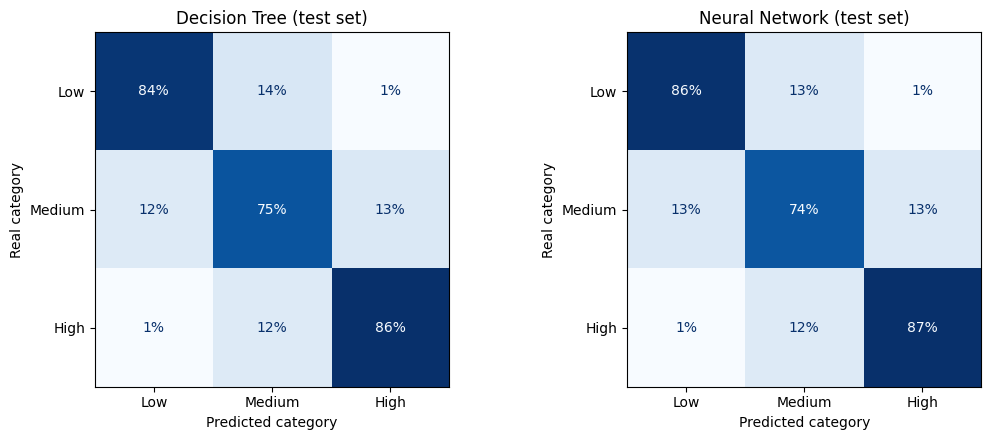


Decision Tree
              precision    recall  f1-score   support

         Low      0.864     0.843     0.853     80359
      Medium      0.736     0.747     0.741     80736
        High      0.855     0.863     0.859     81066

    accuracy                          0.818    242161
   macro avg      0.818     0.818     0.818    242161
weighted avg      0.818     0.818     0.818    242161


Neural Network
              precision    recall  f1-score   support

         Low      0.857     0.857     0.857     80359
      Medium      0.749     0.742     0.746     80736
        High      0.859     0.867     0.863     81066

    accuracy                          0.822    242161
   macro avg      0.822     0.822     0.822    242161
weighted avg      0.822     0.822     0.822    242161



In [ ]:
class_models = {'Decision Tree': (class_tree_model, X_test_ready),
                'Neural Network': (class_nn_model, X_test_scaled)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, (model, X_te)) in zip(axes, class_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_class, model.predict(X_te), labels=class_names,
                                            normalize='true', values_format='.0%', cmap='Blues',
                                            ax=ax, colorbar=False)
    ax.set_title(f'{name} (test set)')
    ax.set_xlabel('Predicted category')
    ax.set_ylabel('Real category')
plt.tight_layout()
plt.show()

for name, (model, X_te) in class_models.items():
    print(f'\n{name}')
    print(classification_report(y_test_class, model.predict(X_te), labels=class_names, digits=3))

**Results:**
* Both models classify about 82% of the test properties correctly (Neural Network Macro-F1 0.822, Decision Tree 0.818), far above the baseline (0.167).
* **Low** and **High** are recognized best (F1 about 0.85–0.86). **Medium** is the hardest category (F1 about 0.74–0.75): it lies between the other two, so its properties can be mistaken in either direction.
* Almost all errors are between neighbouring categories (Low ↔ Medium, Medium ↔ High), typically properties whose price is close to a cut point; mistakes between Low and High are rare.
* The Neural Network is slightly better in every category (F1 Low 0.857 vs 0.853, Medium 0.746 vs 0.741, High 0.863 vs 0.859), but the difference is small.

## 31. Predicting the category from the regression models

Instead of training a separate classifier, we can also get the category from the regression models of section 22:

1. Each regression model predicts the price per m² of every test property.
2. The predicted price is placed in Low, Medium or High using the same cut points as section 25.
3. This predicted category is compared with the real category, using Accuracy and Macro-F1.

The table shows both approaches side by side: the classifiers of sections 28 and 29, which predict the category directly, and the regression models, whose predicted price is turned into a category.

In [ ]:
rows = []

# Classifiers that predict the category directly (sections 28 and 29).
for name, (model, X_te) in class_models.items():
    predicted_class = model.predict(X_te)
    rows.append({'Approach': 'Classifier (category directly)', 'Model': name,
                 'Accuracy': accuracy_score(y_test_class, predicted_class),
                 'Macro-F1': f1_score(y_test_class, predicted_class, average='macro')})

# Regression models: predict the price, then place it in Low / Medium / High.
for name, (model, X_tr, X_te) in final_models.items():
    predicted_class = to_class(np.exp(model.predict(X_te)))  # price prediction -> category
    rows.append({'Approach': 'Regression, then category', 'Model': name,
                 'Accuracy': accuracy_score(y_test_class, predicted_class),
                 'Macro-F1': f1_score(y_test_class, predicted_class, average='macro')})

display(pd.DataFrame(rows).set_index(['Approach', 'Model']).round(3))

Accuracy  Macro-F1
Approach                       Model                                
Classifier (category directly) Decision Tree         0.818     0.818
                               Neural Network        0.822     0.822
Regression, then category      Linear Regression     0.781     0.782
                               Decision Tree         0.817     0.817
                               Neural Network        0.812     0.811

**Results:** for the best models, predicting the category directly and predicting the price first give almost the same result. The classifiers reach a Macro-F1 of 0.818–0.822; through regression, the Decision Tree reaches 0.817, the Neural Network 0.811 and Linear Regression 0.782. A classifier is trained only to place each property on the correct side of the cut points, whereas a regression model is trained to get the exact price right, so a small price error near a cut point can change the category. Among the regression models, the order is the same as in Task A: Decision Tree, then Neural Network, then Linear Regression.

## 32. Prepare the experiment

The proposal asks whether training on more quarters of data gives better predictions. To test this:

1. The **test set is the latest quarter** (2026_Q2), always the same properties.
2. The models are trained on the **last 1, 2, 4 and 8 quarters before it, and then on all earlier quarters**.
3. Each time, we measure the error on the test quarter.

Each training set is different, so the function below repeats the preparation for each one: the outlier boundaries, `District_Price`, `City_Price` and the scaling are learned from **that training set only**.
To keep it fast, only Linear Regression and the Decision Tree are used, and the Region columns are left out (the district and city prices already describe the location).


In [ ]:
from sklearn.preprocessing import TargetEncoder

def quarter_experiment(train_part, test_part):
    # Repeats the preparation steps for one training set, trains two models and scores them on the test quarter.
    train_part, test_part = train_part.copy(), test_part.copy()

    # 1) Outlier boundaries from THIS training set only (log IQR rule per classification, as in section 10).
    q = np.log(train_part['Price_per_m2']).groupby(train_part['Classification']).quantile([0.25, 0.75]).unstack()
    iqr = q[0.75] - q[0.25]
    lower, upper = q[0.25] - 1.5 * iqr, q[0.75] + 1.5 * iqr

    def inside(part):
        log_price = np.log(part['Price_per_m2'])
        return (log_price >= part['Classification'].map(lower)) & (log_price <= part['Classification'].map(upper))

    train_part, test_part = train_part[inside(train_part)].copy(), test_part[inside(test_part)].copy()

    # 2) Location prices learned from THIS training set only (as in section 13).
    for part in (train_part, test_part):
        part['City'] = part['City_District'].str.split('/').str[0].str.strip()
    y_tr, y_te = np.log(train_part['Price_per_m2']), np.log(test_part['Price_per_m2'])
    encoder = TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=42)
    train_location = encoder.fit_transform(train_part[['City_District', 'City']], y_tr)
    test_location = encoder.transform(test_part[['City_District', 'City']])

    def make_inputs(part, location):
        return pd.DataFrame({'Time': part['Time'], 'Num_Properties': part['Num_Properties'],
                             'Log_Area': np.log(part['Area']),
                             'Is_Commercial': (part['Classification'] == 'تجاري').astype(int),
                             'District_Price': location[:, 0], 'City_Price': location[:, 1]}, index=part.index)

    X_tr, X_te = make_inputs(train_part, train_location), make_inputs(test_part, test_location)

    # 3) Scaling for Linear Regression (mean and standard deviation of THIS training set).
    mean, std = X_tr.mean(), X_tr.std().replace(0, 1)

    models = {'Linear Regression': (LinearRegression(), (X_tr - mean) / std, (X_te - mean) / std),
              'Decision Tree': (DecisionTreeRegressor(random_state=42, **best_tree_params), X_tr, X_te)}
    rows = []
    for name, (model, A_tr, A_te) in models.items():
        model.fit(A_tr, y_tr)
        predicted, real = np.exp(model.predict(A_te)), np.exp(y_te)
        error = np.abs(predicted - real)
        rows.append({'Model': name, 'Training rows': len(X_tr),
                     'MAE (SAR/m²)': error.mean(),
                     'Median % error': 100 * np.median(error / real),
                     'R² (log)': r2_score(y_te, np.log(predicted))})
    return rows

## 33. Run the experiment

For each number of quarters, the table shows the size of the training set and the error on the test quarter (2026_Q2):
* **MAE** in SAR/m² (lower is better)
* **Median % error** (lower is better)
* **R² (log)** (higher is better)

The plots show the same as curves: if the error keeps falling to the right, more history helps; if it flattens or rises, older data adds little.

`RUN_QUARTER_EXPERIMENT = False` skips this section, because it takes several minutes.

1 quarter(s) (2026_Q1 to 2026_Q1): done in 1 seconds
2 quarter(s) (2025_Q4 to 2026_Q1): done in 1 seconds
4 quarter(s) (2025_Q2 to 2026_Q1): done in 2 seconds
8 quarter(s) (2024_Q2 to 2026_Q1): done in 5 seconds
21 quarter(s) (2020_Q1 to 2026_Q1): done in 14 seconds
Test quarter: 2026_Q2


,Quarters used,From,To,Model,Training rows,MAE (SAR/m²),Median % error,R² (log)
0,1,2026_Q1,2026_Q1,Linear Regression,31092,793.161,38.313,0.690
1,1,2026_Q1,2026_Q1,Decision Tree,31092,774.983,35.748,0.691
2,2,2025_Q4,2026_Q1,Linear Regression,73432,747.944,35.942,0.700
3,2,2025_Q4,2026_Q1,Decision Tree,73432,719.329,33.028,0.710
4,4,2025_Q2,2026_Q1,Linear Regression,160730,735.491,34.663,0.709
5,4,2025_Q2,2026_Q1,Decision Tree,160730,701.434,32.375,0.720
6,8,2024_Q2,2026_Q1,Linear Regression,401123,740.731,33.906,0.702
7,8,2024_Q2,2026_Q1,Decision Tree,401123,695.694,30.955,0.706
8,21,2020_Q1,2026_Q1,Linear Regression,1202914,822.626,40.347,0.697
9,21,2020_Q1,2026_Q1,Decision Tree,1202914,683.930,32.771,0.726


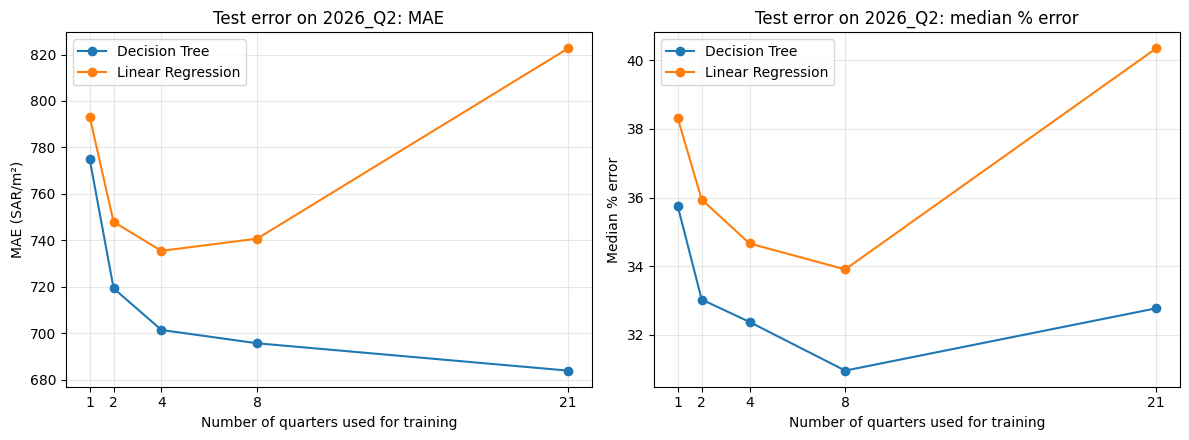

In [ ]:
RUN_QUARTER_EXPERIMENT = True  # Set to False to skip this section.

if RUN_QUARTER_EXPERIMENT:
    quarters_sorted = sorted(df['Source_Quarter'].unique())
    test_quarter = quarters_sorted[-1]    # the latest quarter is the test set
    earlier = quarters_sorted[:-1]        # all quarters before it
    test_part = df[df['Source_Quarter'] == test_quarter]

    quarter_results = []
    for k in [1, 2, 4, 8, len(earlier)]:
        used = earlier[-k:]               # the k quarters just before the test quarter
        start = time.time()
        for row in quarter_experiment(df[df['Source_Quarter'].isin(used)], test_part):
            quarter_results.append({'Quarters used': k, 'From': used[0], 'To': used[-1], **row})
        print(f'{k} quarter(s) ({used[0]} to {used[-1]}): done in {time.time() - start:.0f} seconds')

    quarter_table = pd.DataFrame(quarter_results)
    print('Test quarter:', test_quarter)
    display(quarter_table.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for name, group in quarter_table.groupby('Model'):
        axes[0].plot(group['Quarters used'], group['MAE (SAR/m²)'], marker='o', label=name)
        axes[1].plot(group['Quarters used'], group['Median % error'], marker='o', label=name)
    for ax, label in zip(axes, ['MAE (SAR/m²)', 'Median % error']):
        ax.set_xlabel('Number of quarters used for training')
        ax.set_ylabel(label)
        ax.set_xticks(sorted(quarter_table['Quarters used'].unique()))
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_title(f'Test error on {test_quarter}: MAE')
    axes[1].set_title(f'Test error on {test_quarter}: median % error')
    plt.tight_layout()
    plt.show()

**Results:**
* **More data helps at first:** going from 1 to 4 training quarters reduces the error clearly for both models (Decision Tree MAE 775 → 701 SAR/m², median error 36% → 32%).
* **Beyond about 4–8 quarters, the gain becomes small.** The lowest median error is reached with 8 quarters (Decision Tree 31.0%, Linear Regression 33.9%).
* **Using all quarters since 2020 hurts Linear Regression clearly** (MAE 823, median error 40%). Prices rose strongly between 2020 and 2026, so old transactions pull each district's learned price below its current level, and a single straight-line time trend cannot correct for this. For the **Decision Tree** the result is mixed: all quarters give its lowest MAE (684) and best R² (log) (0.726), but a higher median error than 8 quarters (32.8% vs 31.0%), because it can use separate branches for recent quarters.
* **Conclusion:** the most recent one to two years of data are enough for a good prediction of the next quarter; older history adds little and can hurt simpler models.
* The errors here (MAE about 680–820) are higher than in Task A (about 460–550) because here the models predict a future quarter that is not in the training data, while the main split mixes all years in both training and test sets. This experiment also keeps the national outlier rule, so its numbers are not directly comparable with Task A.

# Summary and demonstration

## 34. Final results

The final test-set results of both tasks in one place.

In [ ]:
regression_test = pd.DataFrame(final_results).query("Set == 'Test'").drop(columns='Set').set_index('Model')
classification_test = pd.DataFrame(classification_results).query("Set == 'Test'").drop(columns='Set').set_index('Model')

print('Task A: Regression (test set)')
display(regression_test.round(3))
print('\n\nTask B: Classification (test set)')
display(classification_test.round(3))

print('\n\nBest regression model (lowest MAE):', regression_test['MAE (SAR/m²)'].idxmin())
print('\nBest classification model (highest Macro-F1):', classification_test['Macro-F1'].idxmax())

Task A: Regression (test set)


,MAE (SAR/m²),RMSE (SAR/m²),Median error (SAR/m²),Median % error,R²,R² (log)
Model,,,,,,
Linear Regression,546.127,1177.510,189.799,32.641,0.633,0.792
Decision Tree,460.033,1027.969,147.532,25.658,0.720,0.825
Neural Network,479.161,1056.636,162.634,27.425,0.704,0.824




Task B: Classification (test set)


,Accuracy,Macro-F1
Model,,
Baseline (most frequent),0.333,0.167
Decision Tree,0.818,0.818
Neural Network,0.822,0.822




Best regression model (lowest MAE): Decision Tree

Best classification model (highest Macro-F1): Neural Network


**Conclusion:** the Decision Tree is the best regression model: it predicts the price per m² with a median error of about 26% (MAE 460 SAR/m², R² 0.720). For the price categories, the Neural Network is slightly ahead (Macro-F1 0.822 vs 0.818 for the tree), with both placing about 82% of properties in the correct category. Location, through the district's typical price, is by far the strongest predictor; time and area add a little. The remaining error mainly reflects information the dataset does not contain, such as the street, the plot's shape and any buildings on it.

## 35. Predict a new transaction

This cell predicts one property with every trained model. The property goes through the same preparation as the training data:
1. Its district and city are turned into `District_Price` and `City_Price` with the encoder fitted in section 13.
2. Its area is put on a log scale, its classification becomes 0/1, and its region becomes the 13 region columns.
3. For Linear Regression and the Neural Networks, it is scaled with the training mean and standard deviation.

The output is the **price per m²** and the **total price** (price per m² × area) from the three regression models, and the **price category** from the two classifiers.

The first example is a property from the Test Set, so its real price is known and can be compared. The second is a new property typed by hand. The typed district name goes through the same cleaning as the data (spaces around `/`, the word `حي`, letter variants), so `الرياض/الياسمين` and `الرياض / حي الياسمين` give the same result. A district never seen in training receives the overall average price, and the prediction then relies mostly on the city and region.

In [ ]:
def predict_transaction(region, city_district, classification, area, num_properties, time_value):
    # Same preparation as the training data, then every trained model makes its prediction.
    city_district = clean_place(city_district)  # same name cleaning as the training data
    city = city_district.split('/')[0].strip()
    location = target_encoder.transform(pd.DataFrame({'City_District': [city_district], 'City': [city]}))
    row = pd.DataFrame({'Time': [time_value], 'Num_Properties': [num_properties], 'Log_Area': [np.log(area)],
                        'Is_Commercial': [int(classification == 'تجاري')],
                        'District_Price': [location[0, 0]], 'City_Price': [location[0, 1]]})
    regions = (pd.get_dummies(pd.Series([region]), prefix='Region', dtype=int)
               .reindex(columns=train_regions.columns, fill_value=0))
    row = pd.concat([row, regions], axis=1)[X_train_ready.columns]  # same columns, same order as training
    row_scaled = (row - training_mean) / training_std

    prices = {name: float(np.exp(model.predict(row if name == 'Decision Tree' else row_scaled))[0])
              for name, (model, X_tr, X_te) in final_models.items()}
    categories = {'Decision Tree': str(class_tree_model.predict(row)[0]),
                  'Neural Network': str(class_nn_model.predict(row_scaled)[0])}
    return prices, categories

def show_prediction(title, region, city_district, classification, area, num_properties, time_value,
                    real_price=None, real_category=None):
    # Print the property, then one table with every model's prediction.
    prices, categories = predict_transaction(region, city_district, classification, area, num_properties, time_value)
    type_name = 'Commercial' if classification == 'تجاري' else 'Residential'
    print(f'{title}\nDistrict: {clean_place(city_district)}\nArea: {area:,.0f} m² | Type: {type_name} | Time: {time_value}')
    if real_price is not None:
        print(f'Real price: {real_price:,.0f} SAR/m² | Real total: {real_price * area:,.0f} SAR | Real category: {real_category}')

    table = pd.DataFrame({'Price per m² (SAR)': prices,
                          'Total price (SAR)': {m: p * area for m, p in prices.items()}})
    if real_price is not None:
        table['Difference from real'] = [f'{100 * (p - real_price) / real_price:+.0f}%' for p in prices.values()]
    table['Category (classifier)'] = pd.Series(categories)
    table = table.fillna('–')  # Linear Regression has no classifier
    display(table.style.format({'Price per m² (SAR)': '{:,.0f}', 'Total price (SAR)': '{:,.0f}'}))
    print()

# Example 1: a property from the Test Set (its real price is known).
i = 0  # change to try another test property
example = X_test.iloc[i]
show_prediction('Example 1: a property from the Test Set', example['Region'], example['City_District'],
                example['Classification'], example['Area'], example['Num_Properties'], example['Time'],
                real_price=y_test.iloc[i], real_category=y_test_class.iloc[i])

# Example 2: a new property typed by hand.
show_prediction('Example 2: a new property', 'منطقة الرياض', 'الرياض/الياسمين', 'سكني', 500, 1, 2026.25)

Example 1: a property from the Test Set
District: جده / الرياض
Area: 625 m² | Type: Residential | Time: 2024.5
Real price: 1,120 SAR/m² | Real total: 700,000 SAR | Real category: Medium


,Price per m² (SAR),Total price (SAR),Difference from real,Category (classifier)
Linear Regression,"1,091","682,003",-3%,–
Decision Tree,"1,135","709,346",+1%,Medium
Neural Network,"1,280","800,129",+14%,Medium



Example 2: a new property
District: الرياض / الياسمين
Area: 500 m² | Type: Residential | Time: 2026.25


,Price per m² (SAR),Total price (SAR),Category (classifier)
Linear Regression,"5,496","2,747,997",–
Decision Tree,"4,836","2,417,799",High
Neural Network,"5,741","2,870,414",High
